# Monitor de Pavimento: Visão Computacional

Global Solution 2026.2 · FIAP · CitizenTech
Nicho: infraestrutura e pavimentação, com detecção de buracos por caixas delimitadoras.

Estrutura: dados (§1), modelo e treinamento (§2), avaliação (§3), desempenho (§4), integração com o CitizenTech (§5) e conclusões (§6).

Cada detecção com confiança ≥ 0,5 é gravada no banco compartilhado (`deteccoes_visao`) e entra na pontuação de prioridade do trecho, usada pelo módulo de GenAI. A detecção apoia a triagem e não substitui a vistoria presencial.

In [1]:
import os, sys, json, time, re, glob, collections, platform, subprocess, random
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, psutil, matplotlib.pyplot as plt
from IPython.display import Markdown, display
import ultralytics
from ultralytics import YOLO

VISAO = Path.cwd().resolve()
if not (VISAO / "detector.py").exists():
    VISAO = (Path.cwd() / "citizentech" / "visao").resolve()
CITIZENTECH, DATASET, EVID = VISAO.parent, VISAO / "dataset", VISAO / "evidencias"
EVID.mkdir(exist_ok=True)
sys.path.insert(0, str(VISAO)); sys.path.insert(0, str(CITIZENTECH))
from detector import DetectorBuracos, medir_latencia, desenhar, Deteccao, CONF_REGISTRO, CONF_EXIBICAO
import banco

# paleta e estilo dos gráficos
PAL = {"azul": "#2a78d6", "laranja": "#eb6834", "aqua": "#1baf7a", "amarelo": "#eda100",
       "vermelho": "#e34948", "cinza": "#898781", "grade": "#e1e0d9", "ink": "#0b0b0b"}
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif", "axes.titleweight": "bold", "axes.titlesize": 11})
def estilo(ax, titulo=None, xlabel=None, ylabel=None):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color("#c3c2b7")
    ax.grid(axis="y", color=PAL["grade"], linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(colors=PAL["cinza"], labelsize=9)
    if titulo: ax.set_title(titulo, loc="left", color=PAL["ink"])
    if xlabel: ax.set_xlabel(xlabel, color=PAL["cinza"])
    if ylabel: ax.set_ylabel(ylabel, color=PAL["cinza"])

def cpu_nome():
    try:
        for l in open("/proc/cpuinfo"):
            if "model name" in l: return l.split(":", 1)[1].strip()
    except Exception: pass
    return platform.processor() or "desconhecido"
HARDWARE = {"cpu": cpu_nome(), "nucleos_fisicos": psutil.cpu_count(logical=False), "threads": psutil.cpu_count(),
            "ram_gb": round(psutil.virtual_memory().total / 1e9, 1), "gpu": "nenhuma (CUDA indisponível)" if not torch.cuda.is_available() else torch.cuda.get_device_name(0),
            "so": platform.platform(), "python": platform.python_version(), "torch": torch.__version__,
            "ultralytics": ultralytics.__version__, "opencv": cv2.__version__, "threads_torch": torch.get_num_threads()}
pd.DataFrame([HARDWARE]).T.rename(columns={0: "valor"})

,valor
cpu,Intel(R) Core(TM) 7 240H
nucleos_fisicos,10
threads,16
ram_gb,33.2
gpu,nenhuma (CUDA indisponível)
so,Linux-7.0.0-42-generic-x86_64-with-glibc2.39
python,3.12.3
torch,2.15.0+cpu
ultralytics,8.4.215
opencv,5.1.0


## 1. Dados

| Base (Hugging Face) | Uso | Licença |
|---|---|---|
| `rupesh002/pothole-detection-dataset` (Roboflow "pothole.v1i", 715 imagens) | treino, validação e teste | MIT |
| `Ryukijano/Pothole-detection-Yolov8` (split de teste, 88 fotos de origem) | teste externo | CC BY 4.0 |

As exportações do Roboflow trazem variações aumentadas da mesma foto (sufixo `.rf.<hash>`). Para evitar vazamento entre conjuntos, `preparar_dados.py` agrupa os arquivos pela foto de origem e divide 70/15/15 por grupo; validação e teste ficam com uma variante por foto. Rótulos inválidos são descartados (um arquivo da base continha texto em vez de coordenadas).

In [2]:
if not (DATASET / "data.yaml").exists():
    subprocess.run([sys.executable, str(VISAO / "preparar_dados.py")], check=True)
print((DATASET / "data.yaml").read_text())

RE_FONTE = re.compile(r"(?:_jpg|_png|_jpeg)?\.rf\.[0-9a-f]+\.(?:jpg|png|jpeg)$", re.I)
fonte = lambda n: RE_FONTE.sub("", n)
def ler_gt(lbl, w=640, h=640):
    out = []
    for l in Path(lbl).read_text().splitlines():
        if not l.strip(): continue
        _, cx, cy, bw, bh = map(float, l.split()[:5])
        out.append([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h])
    return out

linhas, fontes = [], {}
for split in ("train", "val", "test", "test_externo"):
    imgs = sorted((DATASET / split / "images").glob("*.jpg"))
    gts = [ler_gt(DATASET / split / "labels" / (p.stem + ".txt")) for p in imgs]
    fontes[split] = {fonte(p.name) for p in imgs}
    tam = collections.Counter(cv2.imread(str(p)).shape[:2] for p in imgs[:20])
    linhas.append({"conjunto": split, "imagens": len(imgs), "fotos de origem": len(fontes[split]), "caixas": sum(map(len, gts)),
                   "caixas/imagem": round(sum(map(len, gts)) / len(imgs), 2), "resolução": ", ".join(f"{h}x{w}" for (h, w) in tam)})
vaz = {f"{a}∩{b}": len(fontes[a] & fontes[b]) for a, b in (("train", "val"), ("train", "test"), ("val", "test"), ("train", "test_externo"))}
print("Fotos de origem compartilhadas entre conjuntos (deve ser 0):", vaz)
tabela_dados = pd.DataFrame(linhas); tabela_dados

# Gerado por preparar_dados.py (seed 42); divisão por imagem de origem
path: /home/leo/GS-FIAP-Go-Horse-/citizentech/visao/dataset
train: train/images
val: val/images
test: test/images
nc: 1
names: ['buraco']



Fotos de origem compartilhadas entre conjuntos (deve ser 0): {'train∩val': 0, 'train∩test': 0, 'val∩test': 0, 'train∩test_externo': 0}


,conjunto,imagens,fotos de origem,caixas,caixas/imagem,resolução
0,train,501,428,793,1.58,640x640
1,val,92,92,187,2.03,640x640
2,test,93,93,206,2.22,640x640
3,test_externo,88,88,232,2.64,640x640


### 1.2 Amostras rotuladas
Em verde, as caixas anotadas. As imagens vêm em 640×640 e em tons de cinza; o Ultralytics aplica letterbox e normaliza os pixels para 0 a 1.

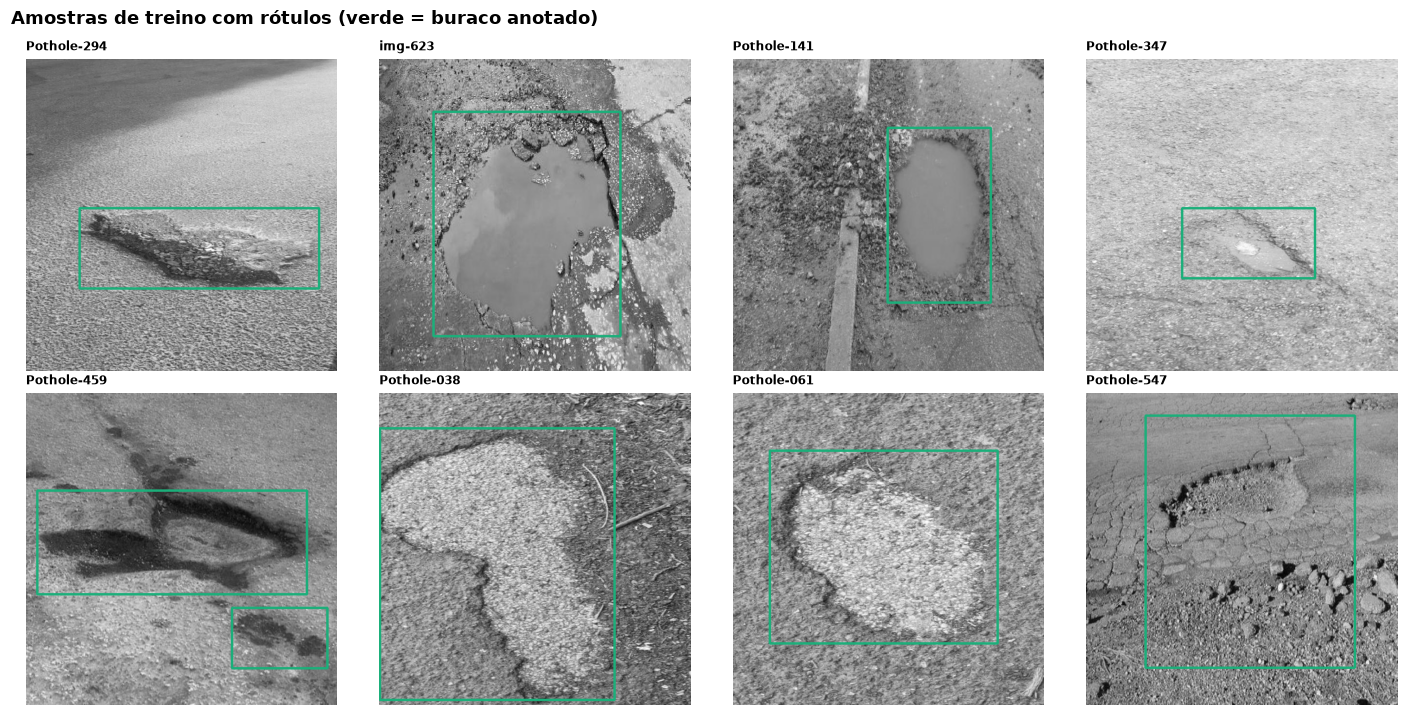

In [3]:
random.seed(7)
amostra = random.sample(sorted((DATASET / "train" / "images").glob("*.jpg")), 8)
fig, axs = plt.subplots(2, 4, figsize=(13, 6.6))
for ax, p in zip(axs.flat, amostra):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    for x1, y1, x2, y2 in ler_gt(DATASET / "train" / "labels" / (p.stem + ".txt")):
        cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (27, 175, 122), 3)
    ax.imshow(im); ax.set_title(fonte(p.name), fontsize=8, loc="left"); ax.axis("off")
plt.suptitle("Amostras de treino com rótulos (verde = buraco anotado)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig(EVID / "amostras_treino.png", bbox_inches="tight"); plt.show()

### 1.3 Tamanho das caixas
Em mediana, um buraco ocupa cerca de 27% do lado da imagem, e um quarto deles fica abaixo de 13%. Esses buracos pequenos perderiam detalhe em 320 px, por isso a entrada fica em 640 px.


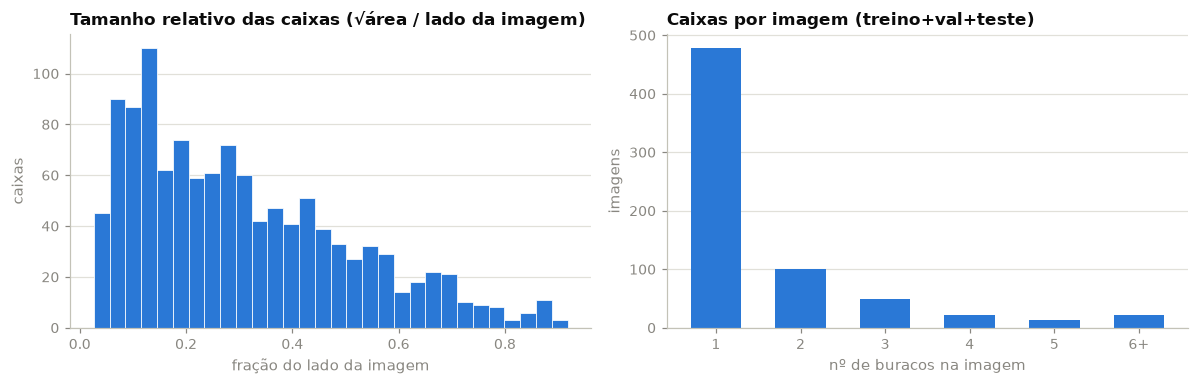

mediana do lado relativo: 0.267 | 25% das caixas abaixo de 0.133 do lado da imagem


In [4]:
areas, por_img = [], []
for split in ("train", "val", "test"):
    for lbl in (DATASET / split / "labels").glob("*.txt"):
        g = ler_gt(lbl); por_img.append(len(g))
        areas += [np.sqrt((x2 - x1) * (y2 - y1)) / 640 for x1, y1, x2, y2 in g]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.hist(areas, bins=30, color=PAL["azul"], edgecolor="white", linewidth=0.5)
estilo(a1, "Tamanho relativo das caixas (√área / lado da imagem)", "fração do lado da imagem", "caixas")
cont = collections.Counter(min(n, 6) for n in por_img)
a2.bar([str(k) if k < 6 else "6+" for k in sorted(cont)], [cont[k] for k in sorted(cont)], color=PAL["azul"], width=0.6)
estilo(a2, "Caixas por imagem (treino+val+teste)", "nº de buracos na imagem", "imagens")
plt.tight_layout(); plt.savefig(EVID / "distribuicao_caixas.png", bbox_inches="tight"); plt.show()
print(f"mediana do lado relativo: {np.median(areas):.3f} | 25% das caixas abaixo de {np.percentile(areas, 25):.3f} do lado da imagem")

## 2. Modelo e treinamento

- **Tarefa:** detecção com caixas, para saber onde e quantos buracos há em cada imagem.
- **Arquitetura:** YOLO11n (Ultralytics), detector de um estágio com ~2,6 M de parâmetros, escolhido por rodar em CPU e caber em hardware embarcado.
- **Transfer learning:** pesos do COCO com ajuste fino de todas as camadas (501 imagens de treino).
- **Aumento de dados (só no treino):** mosaico, HSV, translação, escala e espelhamento; mosaico desligado nas 5 últimas épocas.
- **Hiperparâmetros:** 30 épocas, lote 8, AdamW (lr 0,002, escolhido automaticamente), paciência 10, semente 42.

O treino foi feito com `treinar.py` (~100 min em CPU). O notebook reutiliza `modelos/best.pt`; use `TREINAR = True` para refazer.

In [5]:
TREINAR = False
RUN = VISAO / "runs" / "yolo11n_buracos"
PESOS = VISAO / "modelos" / "best.pt"
print("Comando usado:  python citizentech/visao/treinar.py --epochs 30 --batch 8 --imgsz 640")
if TREINAR or not PESOS.exists():
    subprocess.run([sys.executable, str(VISAO / "treinar.py"), "--epochs", "30", "--batch", "8", "--imgsz", "640"], check=True)
import yaml
args = yaml.safe_load((RUN / "args.yaml").read_text())
chaves = ["model", "data", "epochs", "batch", "imgsz", "optimizer", "lr0", "momentum", "weight_decay", "patience", "close_mosaic",
          "mosaic", "fliplr", "hsv_h", "hsv_s", "hsv_v", "scale", "translate", "seed", "device", "workers"]
pd.DataFrame({"parâmetro": chaves, "valor": [args.get(k) for k in chaves]})

Comando usado:  python citizentech/visao/treinar.py --epochs 30 --batch 8 --imgsz 640


,parâmetro,valor
0,model,yolo11n.pt
1,data,/home/leo/GS-FIAP-Go-Horse-/citizentech/visao/...
2,epochs,30
3,batch,8
4,imgsz,640
5,optimizer,auto
6,lr0,0.01
7,momentum,0.937
8,weight_decay,0.0005
9,patience,10


YOLO11n ajustado: 320 camadas · 2.60 M parâmetros · 6.6 GFLOPs (640x640) · classes: {0: 'buraco'}
Épocas executadas: 30 · melhor época (mAP50-95 de validação): 27


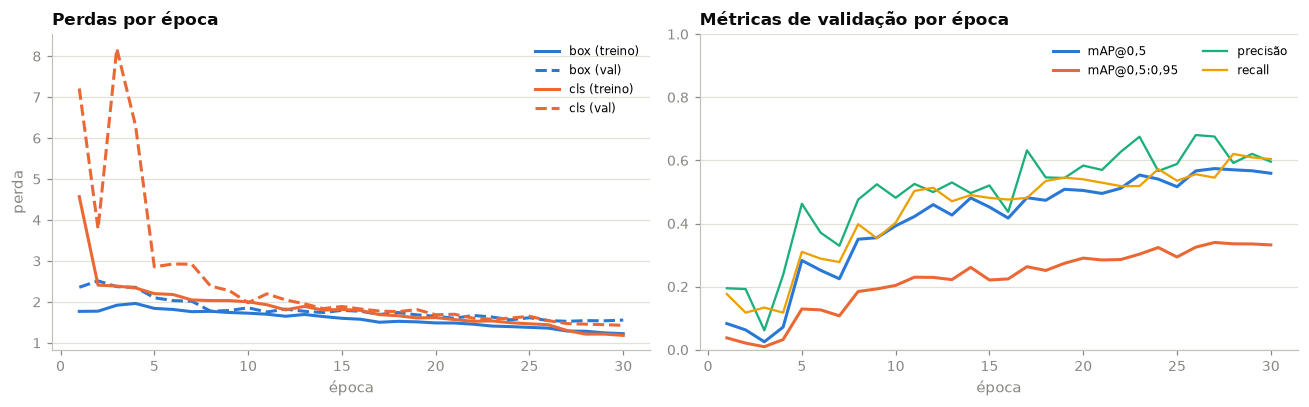

In [6]:
model = YOLO(str(PESOS))
from ultralytics.utils.torch_utils import get_flops
# parâmetros e GFLOPs do modelo ajustado
n_camadas, n_params, gflops = len(list(model.model.modules())), sum(p.numel() for p in model.model.parameters()), get_flops(model.model, 640)
print(f"YOLO11n ajustado: {n_camadas} camadas · {n_params/1e6:.2f} M parâmetros · {gflops:.1f} GFLOPs (640x640) · classes: {model.names}")
res = pd.read_csv(RUN / "results.csv"); res.columns = [c.strip() for c in res.columns]
melhor = res.loc[res["metrics/mAP50-95(B)"].idxmax()]
print(f"Épocas executadas: {len(res)} · melhor época (mAP50-95 de validação): {int(melhor['epoch'])}")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(res["epoch"], res["train/box_loss"], color=PAL["azul"], lw=2, label="box (treino)")
a1.plot(res["epoch"], res["val/box_loss"], color=PAL["azul"], lw=2, ls="--", label="box (val)")
a1.plot(res["epoch"], res["train/cls_loss"], color=PAL["laranja"], lw=2, label="cls (treino)")
a1.plot(res["epoch"], res["val/cls_loss"], color=PAL["laranja"], lw=2, ls="--", label="cls (val)")
estilo(a1, "Perdas por época", "época", "perda"); a1.legend(frameon=False, fontsize=8)
a2.plot(res["epoch"], res["metrics/mAP50(B)"], color=PAL["azul"], lw=2, label="mAP@0,5")
a2.plot(res["epoch"], res["metrics/mAP50-95(B)"], color=PAL["laranja"], lw=2, label="mAP@0,5:0,95")
a2.plot(res["epoch"], res["metrics/precision(B)"], color=PAL["aqua"], lw=1.5, label="precisão")
a2.plot(res["epoch"], res["metrics/recall(B)"], color=PAL["amarelo"], lw=1.5, label="recall")
a2.set_ylim(0, 1); estilo(a2, "Métricas de validação por época", "época"); a2.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(EVID / "curvas_treino.png", bbox_inches="tight"); plt.show()

## 3. Avaliação

### 3.1 Métricas de detecção
Precisão, recall, mAP@0,5 e mAP@0,5:0,95 no teste (93 fotos) e no teste externo (88 fotos de outra base). A matriz de confusão usa confiança ≥ 0,25 e IoU ≥ 0,45.

In [7]:
def avaliar(data_yaml, split, nome):
    m = model.val(data=str(data_yaml), split=split, imgsz=640, batch=8, device="cpu", plots=True,
                  project=str(VISAO / "runs"), name=nome, exist_ok=True, verbose=False)
    # matriz de confusão com conf=0,25 (a passada do mAP usa conf=0,001)
    m25 = model.val(data=str(data_yaml), split=split, imgsz=640, batch=8, device="cpu", conf=0.25, plots=True,
                    project=str(VISAO / "runs"), name=nome + "_conf025", exist_ok=True, verbose=False)
    cm = m25.confusion_matrix.matrix  # linhas: previsto; colunas: real
    return {"conjunto": nome, "precisão": m.box.mp, "recall": m.box.mr, "mAP@0,5": m.box.map50, "mAP@0,5:0,95": m.box.map,
            "VP": int(cm[0, 0]), "FP": int(cm[0, 1]), "FN": int(cm[1, 0])}
r_teste = avaliar(DATASET / "data.yaml", "test", "val_teste")
r_ext = avaliar(DATASET / "data_externo.yaml", "val", "val_teste_externo")
metricas = pd.DataFrame([r_teste, r_ext]).set_index("conjunto")
metricas.style.format({"precisão": "{:.3f}", "recall": "{:.3f}", "mAP@0,5": "{:.3f}", "mAP@0,5:0,95": "{:.3f}"})

Ultralytics 8.4.215 🚀 Python-3.12.3 torch-2.15.0+cpu CPU (Intel Core 7 240H)


YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 328.6±449.3 MB/s, size: 86.8 KB)


val: Scanning /home/leo/GS-FIAP-Go-Horse-/citizentech/visao/dataset/test/labels.cache... 93 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 93/93 12.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 8% ━─────────── 1/12 2.8s/it 0.8s<30.8s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 16% ━━────────── 2/12 1.6s/it 1.6s<16.1s

... (65 outputs left out)

                   all         88        232      0.663      0.297      0.266      0.125


Speed: 2.1ms preprocess, 75.6ms inference, 0.0ms loss, 1.1ms postprocess per image


Results saved to /home/leo/GS-FIAP-Go-Horse-/citizentech/visao/runs/val_teste_externo_conf025


,precisão,recall,"mAP@0,5","mAP@0,5:0,95",VP,FP,FN
conjunto,,,,,,,
val_teste,0.755,0.626,0.703,0.421,132,54,74
val_teste_externo,0.596,0.319,0.368,0.166,69,35,163


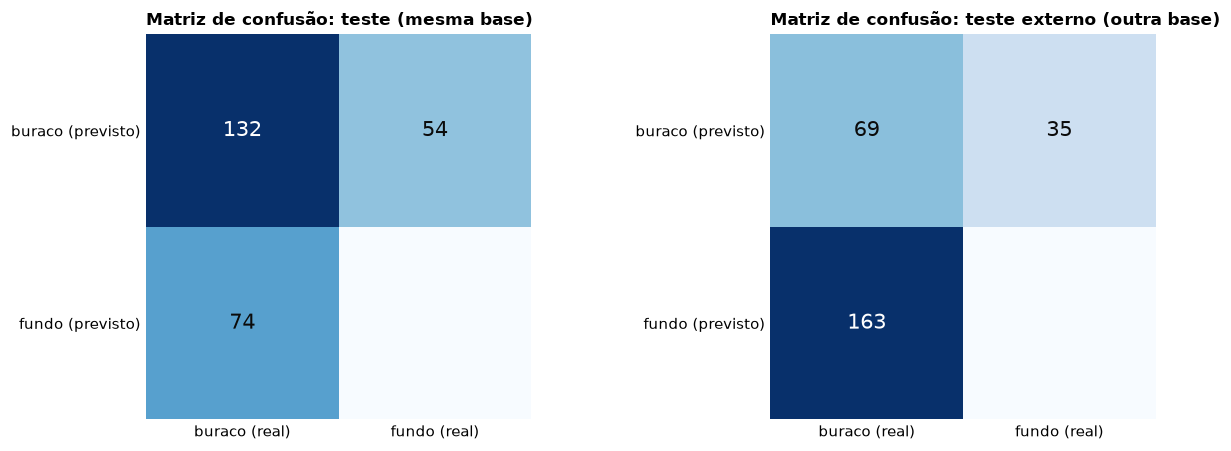

**Curva precisão × recall (teste, gerada pelo Ultralytics):**

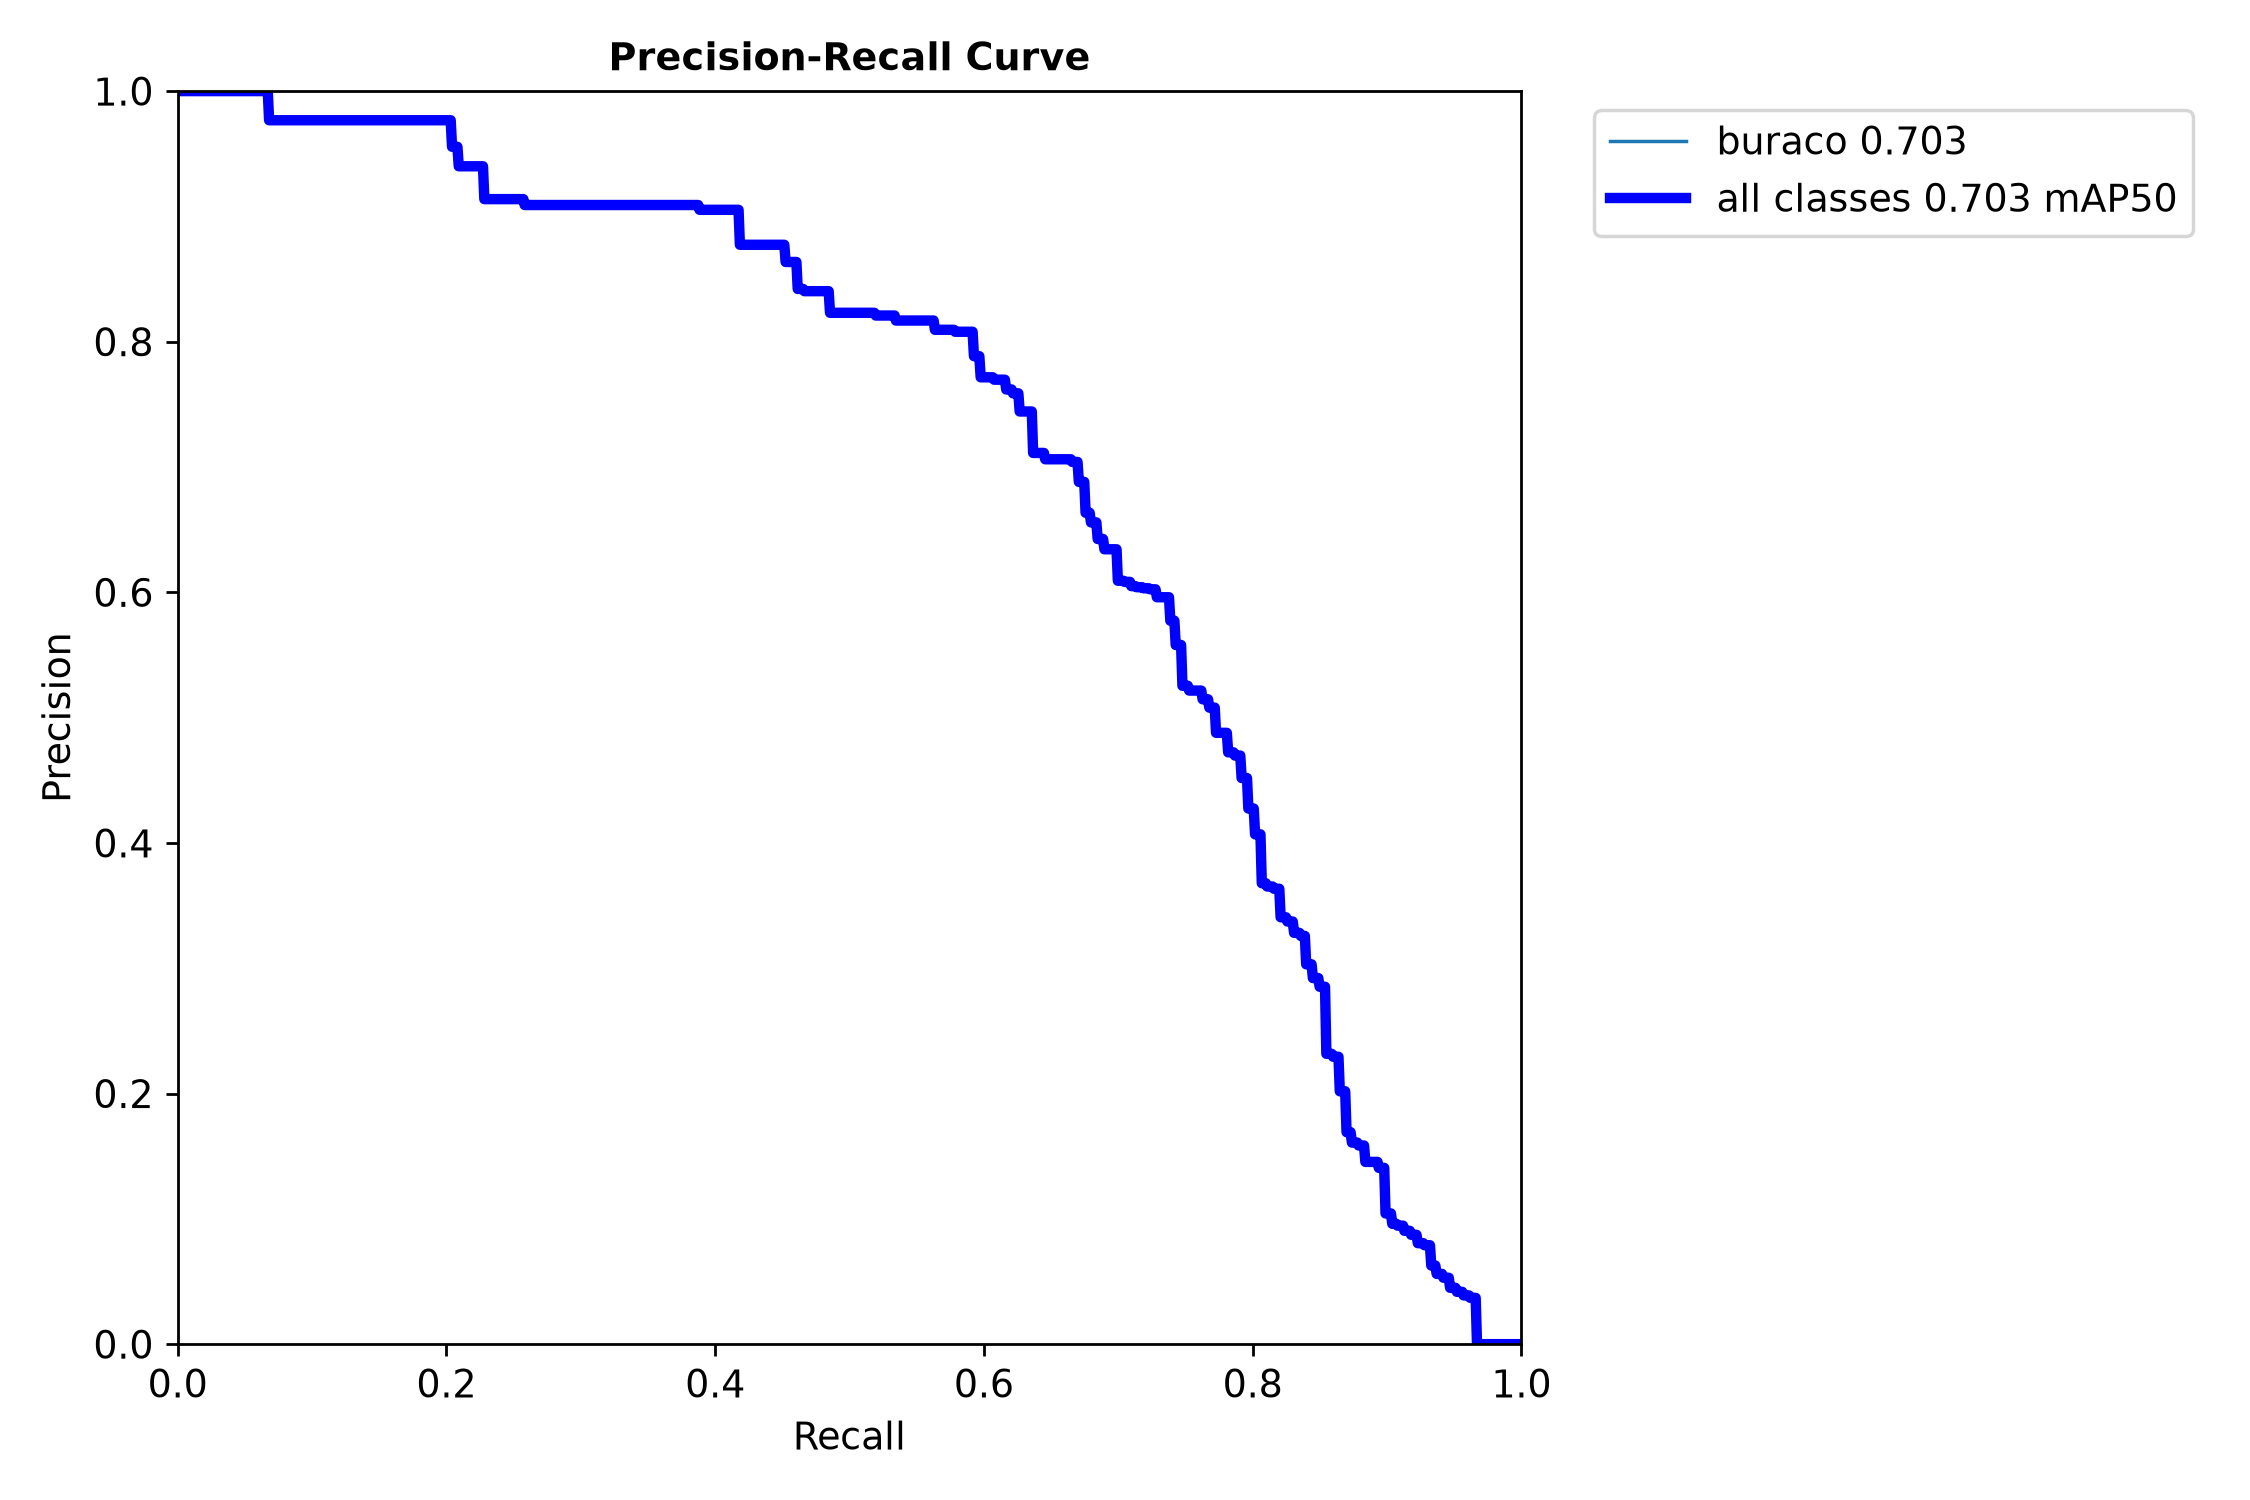

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (nome, r) in zip(axs, (("teste (mesma base)", r_teste), ("teste externo (outra base)", r_ext))):
    m = np.array([[r["VP"], r["FP"]], [r["FN"], 0]])
    ax.imshow(m, cmap="Blues", vmin=0, vmax=max(1, m.max()))
    for (i, j), v in np.ndenumerate(m):
        if (i, j) != (1, 1): ax.text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > m.max() * 0.6 else PAL["ink"])
    ax.set_xticks([0, 1]); ax.set_xticklabels(["buraco (real)", "fundo (real)"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["buraco (previsto)", "fundo (previsto)"])
    ax.set_title(f"Matriz de confusão: {nome}", loc="left", fontweight="bold"); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.savefig(EVID / "matriz_confusao.png", bbox_inches="tight"); plt.show()
from IPython.display import Image as IPImage
display(Markdown("**Curva precisão × recall (teste, gerada pelo Ultralytics):**"))
display(IPImage(filename=str(VISAO / "runs" / "val_teste" / "BoxPR_curve.png"), width=520))

### 3.2 Limiar de confiança
Precisão, recall e F1 por limiar no conjunto de teste, com pareamento por IoU ≥ 0,5. Na integração há dois limiares: 0,25 para exibir a caixa como incerta e 0,50 para gravar no banco. Assim a tela privilegia o recall e o que altera a prioridade do trecho exige mais precisão.

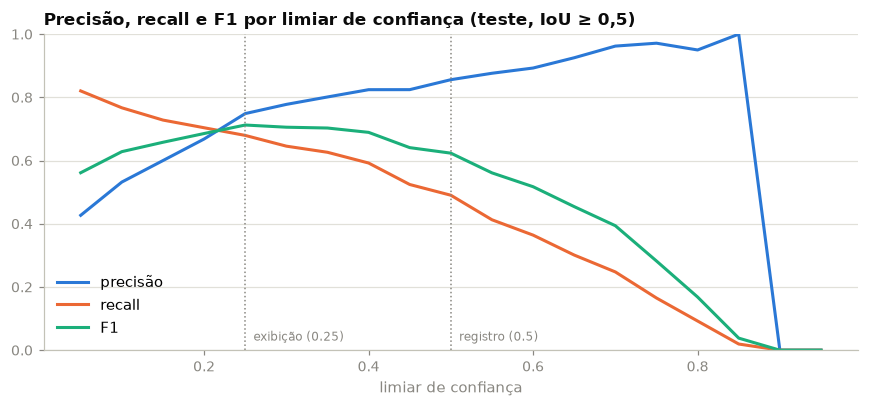

Melhor F1 = 0.712 no limiar 0.25


,limiar,precisão,recall,F1,VP,FP,FN
1,0.10,0.532,0.767,0.628,158,139,48
4,0.25,0.749,0.680,0.712,140,47,66
7,0.40,0.824,0.592,0.689,122,26,84
9,0.50,0.856,0.490,0.623,101,17,105
11,0.60,0.893,0.364,0.517,75,9,131
14,0.75,0.971,0.165,0.282,34,1,172


In [9]:
# IoU entre duas caixas [x1, y1, x2, y2]
def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    return inter / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter + 1e-9)

# previsões (conf ≥ 0,001) e rótulos de todas as imagens de um conjunto
def prever_tudo(split):
    imgs = sorted((DATASET / split / "images").glob("*.jpg"))
    preds, gts = {}, {}
    for r in model.predict([str(p) for p in imgs], conf=0.001, imgsz=640, device="cpu", stream=True, verbose=False):
        k = Path(r.path).name
        b = r.boxes.xyxy.cpu().numpy(); c = r.boxes.conf.cpu().numpy()
        preds[k] = sorted([[*bb, cc] for bb, cc in zip(b.tolist(), c.tolist())], key=lambda x: -x[4])
        gts[k] = ler_gt(DATASET / split / "labels" / (Path(k).stem + ".txt"))
    return preds, gts

# pareamento guloso por confiança: VP, FP e FN para um limiar
def casar(preds, gts, thr, iou_thr=0.5):
    tp = fp = fn = 0; detalhes = {}
    for k, g in gts.items():
        usados, fps, tps = set(), [], []
        for box in preds.get(k, []):
            if box[4] < thr: continue
            best, bi = 0, -1
            for j, gb in enumerate(g):
                if j in usados: continue
                v = iou(box[:4], gb)
                if v > best: best, bi = v, j
            if best >= iou_thr: tp += 1; usados.add(bi); tps.append(box)
            else: fp += 1; fps.append(box)
        fns = [gb for j, gb in enumerate(g) if j not in usados]; fn += len(fns)
        detalhes[k] = {"tp": tps, "fp": fps, "fn": fns}
    P = tp / (tp + fp) if tp + fp else 0.0; R = tp / (tp + fn) if tp + fn else 0.0
    return {"limiar": thr, "precisão": P, "recall": R, "F1": 2 * P * R / (P + R) if P + R else 0.0, "VP": tp, "FP": fp, "FN": fn}, detalhes

# curva precisão/recall/F1 por limiar
preds_teste, gts_teste = prever_tudo("test")
limiares = np.round(np.arange(0.05, 0.96, 0.05), 2)
sweep = pd.DataFrame([casar(preds_teste, gts_teste, t)[0] for t in limiares])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sweep["limiar"], sweep["precisão"], color=PAL["azul"], lw=2, label="precisão")
ax.plot(sweep["limiar"], sweep["recall"], color=PAL["laranja"], lw=2, label="recall")
ax.plot(sweep["limiar"], sweep["F1"], color=PAL["aqua"], lw=2, label="F1")
for t, lab in ((CONF_EXIBICAO, "exibição"), (CONF_REGISTRO, "registro")):
    ax.axvline(t, color=PAL["cinza"], lw=1, ls=":"); ax.text(t + 0.01, 0.03, f"{lab} ({t})", color=PAL["cinza"], fontsize=8)
ax.set_ylim(0, 1); estilo(ax, "Precisão, recall e F1 por limiar de confiança (teste, IoU ≥ 0,5)", "limiar de confiança"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(EVID / "limiar_confianca.png", bbox_inches="tight"); plt.show()
melhor_f1 = sweep.loc[sweep["F1"].idxmax()]
print(f"Melhor F1 = {melhor_f1['F1']:.3f} no limiar {melhor_f1['limiar']}")
sweep[sweep["limiar"].isin([0.1, 0.25, 0.4, 0.5, 0.6, 0.75])].round(3)

### 3.3 Acertos e erros
Limiar 0,5. Verde: rótulo; vermelho: acerto; laranja: falso positivo; "FN": buraco não detectado. As duas primeiras linhas são as imagens com mais erros e a última, acertos.

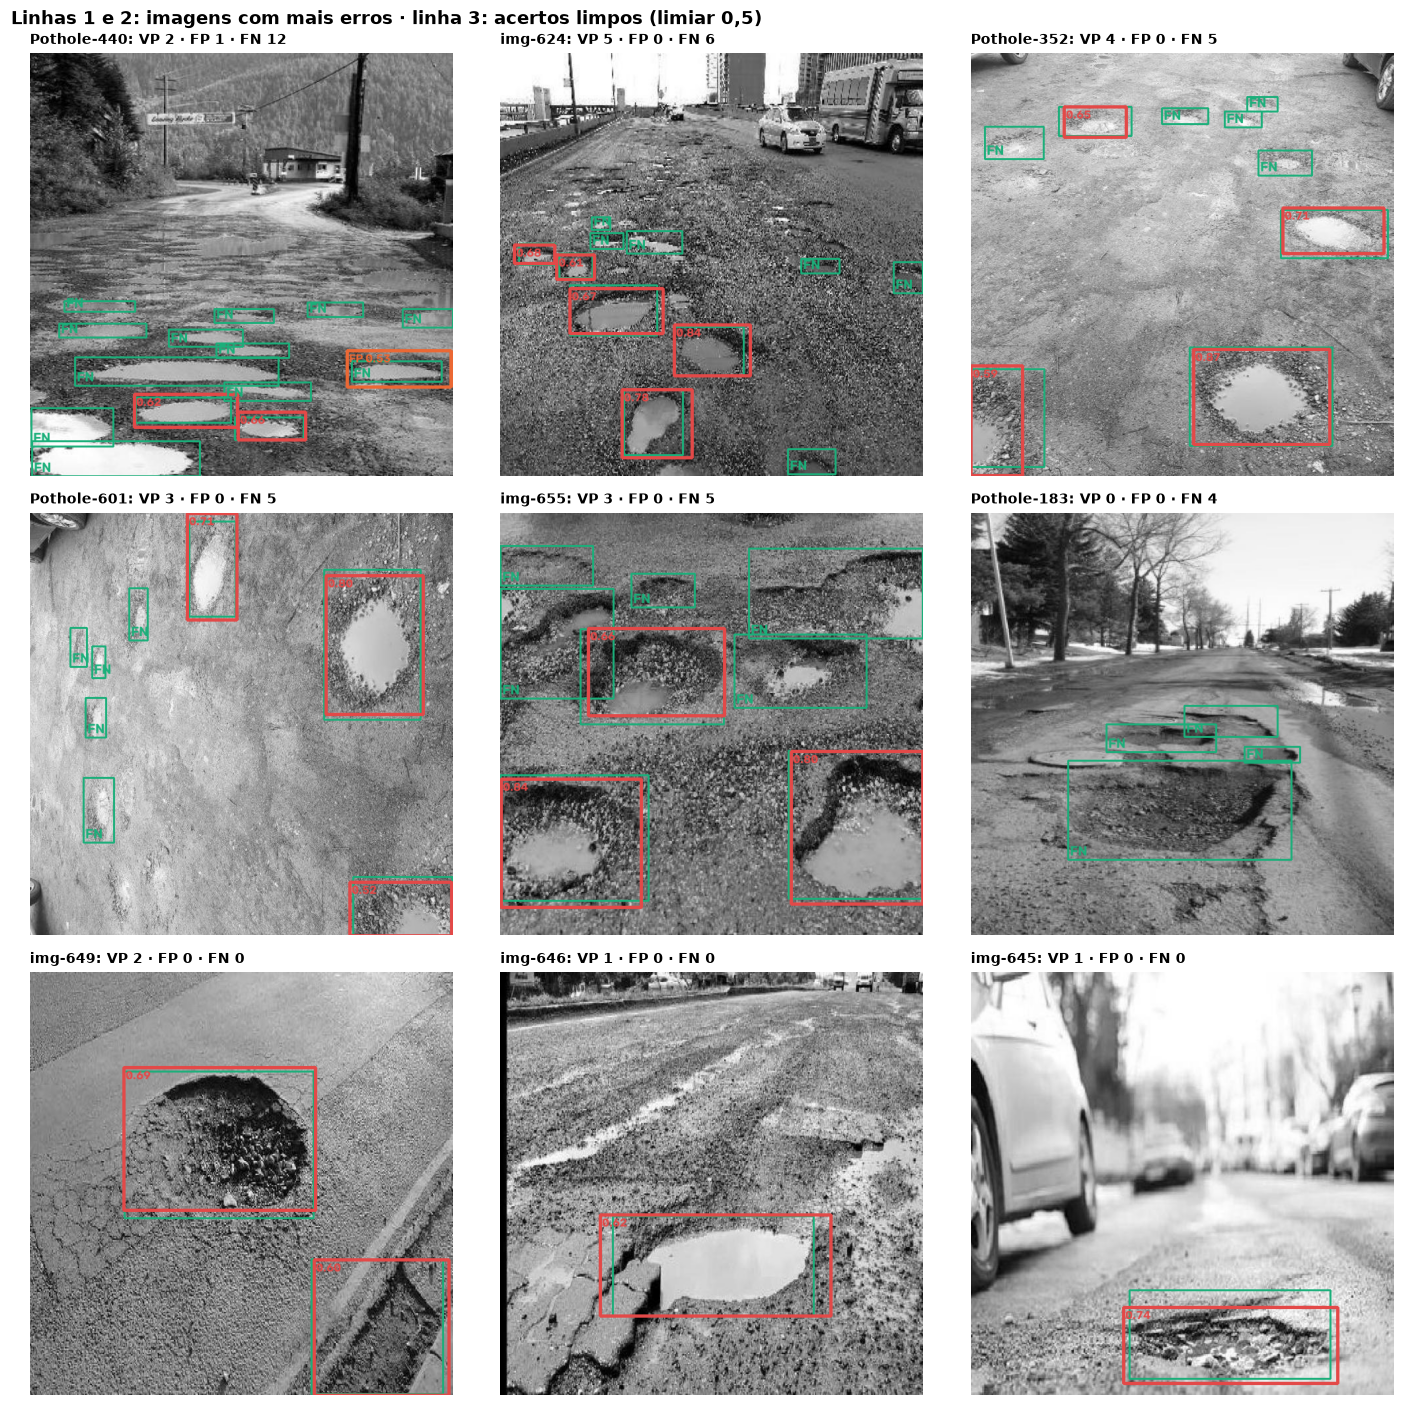

No limiar 0,5: 101 VP, 17 FP, 105 FN em 93 imagens · imagens com algum erro: 53


In [10]:
_, det05 = casar(preds_teste, gts_teste, CONF_REGISTRO)
ordem = sorted(det05, key=lambda k: -(len(det05[k]["fp"]) + len(det05[k]["fn"])))
piores = ordem[:6]
limpos = [k for k in ordem[::-1] if det05[k]["tp"] and not det05[k]["fp"] and not det05[k]["fn"]][:3]

def pintar(k, info):
    im = cv2.cvtColor(cv2.imread(str(DATASET / "test" / "images" / k)), cv2.COLOR_BGR2RGB)
    for x1, y1, x2, y2 in gts_teste[k]: cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (27, 175, 122), 2)
    for x1, y1, x2, y2, c in info["tp"]: cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (227, 73, 72), 3); cv2.putText(im, f"{c:.2f}", (int(x1)+3, int(y1)+18), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (227, 73, 72), 2)
    for x1, y1, x2, y2, c in info["fp"]: cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (235, 104, 52), 3); cv2.putText(im, f"FP {c:.2f}", (int(x1)+3, int(y1)+18), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (235, 104, 52), 2)
    for x1, y1, x2, y2 in info["fn"]: cv2.putText(im, "FN", (int(x1)+3, int(y2)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (27, 175, 122), 2)
    return im

fig, axs = plt.subplots(3, 3, figsize=(13, 13))
for ax, k in zip(axs.flat, piores + limpos):
    i = det05[k]; ax.imshow(pintar(k, i)); ax.axis("off")
    ax.set_title(f"{fonte(k)}: VP {len(i['tp'])} · FP {len(i['fp'])} · FN {len(i['fn'])}", fontsize=9, loc="left")
plt.suptitle("Linhas 1 e 2: imagens com mais erros · linha 3: acertos limpos (limiar 0,5)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig(EVID / "analise_erros.png", bbox_inches="tight"); plt.show()
tot = casar(preds_teste, gts_teste, CONF_REGISTRO)[0]
print(f"No limiar 0,5: {tot['VP']} VP, {tot['FP']} FP, {tot['FN']} FN em {len(gts_teste)} imagens · "
      f"imagens com algum erro: {sum(1 for k in det05 if det05[k]['fp'] or det05[k]['fn'])}")

Padrões observados:
- Falsos negativos: buracos pequenos ou distantes, cobertos por água ou sombra, e grupos de buracos próximos que o modelo junta numa caixa só.
- Falsos positivos: remendos escuros, manchas, tampas de bueiro e sombras com borda nítida. Alguns são buracos reais sem rótulo.
- Iluminação forte reduz a confiança: várias detecções corretas ficam entre 0,25 e 0,5.

## 4. Desempenho
Latência por imagem (lote 1, com pré e pós-processamento) e FPS em CPU, sem GPU, para três resoluções de entrada. Medição feita com o notebook na bateria, em modo de economia de energia (cerca de 2 GHz). Na tomada e com a máquina ociosa, a mesma medição deu cerca de 23, 35 e 48 ms (43, 28 e 21 FPS): a latência depende bastante do modo de energia e da carga da CPU.


,imgsz,n,latencia_media_ms,latencia_p95_ms,fps,hardware
0,320,30,37.4,47.0,26.7,Intel(R) Core(TM) 7 240H
1,480,30,49.4,53.9,20.2,Intel(R) Core(TM) 7 240H
2,640,30,79.3,87.0,12.6,Intel(R) Core(TM) 7 240H


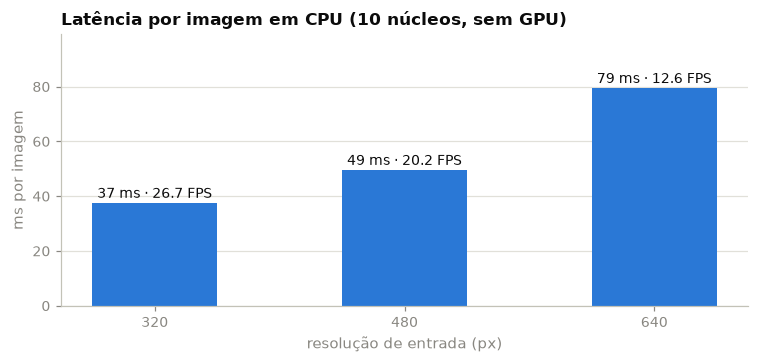

In [11]:
det = DetectorBuracos(PESOS, imgsz=640)
imgs_bench = [str(p) for p in sorted((DATASET / "test" / "images").glob("*.jpg"))[:30]]
bench = pd.DataFrame([medir_latencia(det, imgs_bench, imgsz=s) for s in (320, 480, 640)])
bench["hardware"] = HARDWARE["cpu"]
display(bench.round(1))
fig, ax = plt.subplots(figsize=(7, 3.4))
barras = ax.bar(bench["imgsz"].astype(str), bench["latencia_media_ms"], color=PAL["azul"], width=0.5)
for b, (lat, fps) in zip(barras, zip(bench["latencia_media_ms"], bench["fps"])):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f"{lat:.0f} ms · {fps:.1f} FPS", ha="center", fontsize=9, color=PAL["ink"])
estilo(ax, f"Latência por imagem em CPU ({HARDWARE['nucleos_fisicos']} núcleos, sem GPU)", "resolução de entrada (px)", "ms por imagem")
ax.set_ylim(0, bench["latencia_media_ms"].max() * 1.25)
plt.tight_layout(); plt.savefig(EVID / "latencia.png", bbox_inches="tight"); plt.show()

A entrada de 640 px foi mantida por causa dos buracos pequenos; com `stride` no vídeo, o processamento fica próximo do tempo real. Em hardware mais fraco, 480 px é o primeiro ajuste. Exportar para ONNX/OpenVINO com INT8 fica como evolução.

## 5. Integração com o CitizenTech

### 5.1 Imagem estática
`detectar_imagem()` retorna caixas, confiança e a imagem anotada; `registrar_no_banco()` grava as detecções confirmadas e a pontuação do trecho é atualizada na hora.

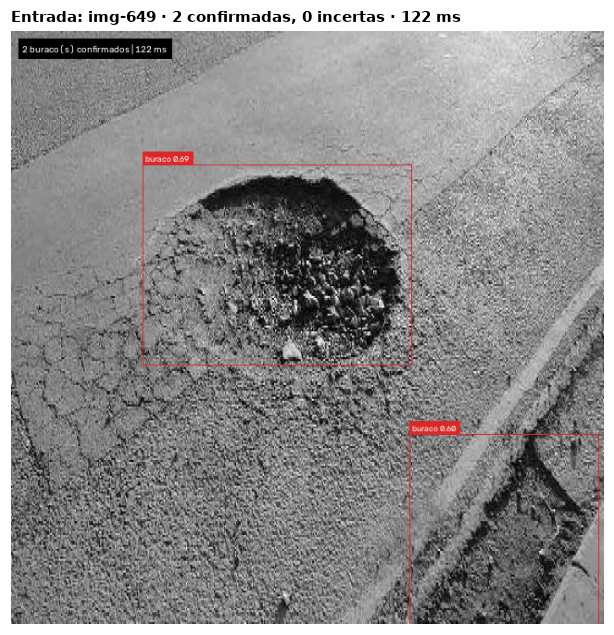

,classe,confiança,bbox,registra?
0,buraco,0.687,"[142, 144, 432, 360]",True
1,buraco,0.602,"[430, 435, 634, 640]",True


2 detecções gravadas em deteccoes_visao para Av. Jabaquara, 500-900


,momento,deteccoes_visao,pontuacao,nivel
0,antes,0,0.0,sem_registro
1,depois,2,4.0,media


In [12]:
conn = banco.conectar(); banco.inicializar(conn)
conn.execute("DELETE FROM deteccoes_visao WHERE arquivo LIKE 'nb_%'"); conn.commit()   # permite reexecutar a célula
TRECHO_FOTO = "SIM0004"   # trecho sem registros
antes = banco.prioridade_do_trecho(conn, TRECHO_FOTO)
exemplo = next(k for k in ordem[::-1] if len(det05[k]["tp"]) >= 2)
r = det.detectar_imagem(str(DATASET / "test" / "images" / exemplo))
plt.figure(figsize=(7, 7)); plt.imshow(cv2.cvtColor(r.imagem_anotada, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"Entrada: {fonte(exemplo)} · {len(r.confirmadas)} confirmadas, {len(r.deteccoes)-len(r.confirmadas)} incertas · {r.latencia_ms:.0f} ms", loc="left", fontsize=10, fontweight="bold")
plt.savefig(EVID / "integracao_imagem.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame([{"classe": d.classe, "confiança": round(d.confianca, 3), "bbox": d.bbox, "registra?": d.confianca >= CONF_REGISTRO} for d in r.deteccoes]))
n = det.registrar_no_banco(conn, TRECHO_FOTO, "nb_" + exemplo, r.deteccoes)
depois = banco.prioridade_do_trecho(conn, TRECHO_FOTO)
print(f"{n} detecções gravadas em deteccoes_visao para {depois['nome']}")
pd.DataFrame([{"momento": "antes", **{k: antes[k] for k in ("deteccoes_visao", "pontuacao", "nivel")}},
              {"momento": "depois", **{k: depois[k] for k in ("deteccoes_visao", "pontuacao", "nivel")}}])

### 5.2 Vídeo (monitoramento contínuo)
`processar_video()` usa rastreamento (ByteTrack): cada buraco recebe um identificador e é gravado uma única vez, com a maior confiança observada. O notebook usa o vídeo mais recente da raiz do repositório ou de `midia/`; sem vídeo, monta uma sequência a partir de fotos de teste.

In [13]:
MIDIA = CITIZENTECH.parent / "midia"
# vídeo mais recente da raiz do repositório ou de midia/
videos = sorted({p for pasta in (CITIZENTECH.parent, MIDIA) for ext in ("*.mp4", "*.MP4", "*.mov", "*.MOV", "*.avi", "*.webm")
                 for p in pasta.glob(ext)}, key=lambda p: p.stat().st_mtime)
if videos:
    VIDEO, TRECHO_VIDEO, STRIDE = videos[-1], "SIM0005", 2
    if not banco.trecho_existe(conn, TRECHO_VIDEO):
        banco.cadastrar_trecho(conn, TRECHO_VIDEO, "Via filmada (vídeo real)", "não informado")
    print("Vídeo real encontrado:", VIDEO.name)
else:
    VIDEO, TRECHO_VIDEO, STRIDE = VISAO / "saida" / "nb_sequencia_teste.mp4", "SIM0001", 1
    VIDEO.parent.mkdir(exist_ok=True)
    random.seed(3); fotos = random.sample(sorted((DATASET / "test_externo" / "images").glob("*.jpg")), 24)
    vw = cv2.VideoWriter(str(VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), 10, (960, 540))
    for p in fotos:  # simula a câmera avançando sobre a foto
        im = cv2.imread(str(p)); h, w = im.shape[:2]
        for i in range(12):
            z = 1.0 + 0.35 * i / 11; cw, ch = int(w / z), int(w / z * 9 / 16)
            x0, y0 = (w - cw) // 2, min(h - ch, int((h - ch) * 0.55 + 0.3 * ch * i / 11))
            vw.write(cv2.resize(im[y0:y0 + ch, x0:x0 + cw], (960, 540)))
    vw.release(); print("Sequência sintética criada a partir de 24 fotos do teste externo:", VIDEO.name)

conn.execute("DELETE FROM deteccoes_visao WHERE arquivo = ? AND trecho_uid = ?", (VIDEO.name, TRECHO_VIDEO)); conn.commit()
antes_v = banco.prioridade_do_trecho(conn, TRECHO_VIDEO)
SAIDA = VISAO / "saida" / (VIDEO.stem + "_anotado.mp4")
rv = det.processar_video(VIDEO, SAIDA, stride=STRIDE, trecho=TRECHO_VIDEO, conn=conn, progresso=False)
depois_v = banco.prioridade_do_trecho(conn, TRECHO_VIDEO)
resumo_video = {"vídeo": VIDEO.name, "resolução": f"{rv.largura}x{rv.altura}", "fps do vídeo": round(rv.fps_video, 1), "quadros lidos": rv.frames_lidos,
                "quadros processados": rv.frames_processados, "stride": STRIDE, "latência média (ms/quadro)": round(rv.latencia_media_ms, 1),
                "FPS de processamento": round(rv.fps_processamento, 2), "tempo total (s)": round(rv.tempo_total_s, 1),
                "buracos rastreados": len(rv.buracos_rastreados), "buracos confirmados (≥0,5)": len(rv.buracos_confirmados),
                "registros gravados no banco": rv.registros_banco, "trecho": f"{TRECHO_VIDEO} · {depois_v['nome']}",
                "pontuação antes → depois": f"{antes_v['pontuacao']} ({antes_v['nivel']}) → {depois_v['pontuacao']} ({depois_v['nivel']})"}
display(pd.DataFrame([resumo_video]).T.rename(columns={0: "valor"}))
print("Vídeo anotado salvo em", SAIDA)

Vídeo real encontrado: WhatsApp Video 2026-11-17 at 17.49.06.mp4


,valor
vídeo,WhatsApp Video 2026-11-17 at 17.49.06.mp4
resolução,848x478
fps do vídeo,30.0
quadros lidos,1474
quadros processados,737
stride,2
latência média (ms/quadro),58.1
FPS de processamento,13.99
tempo total (s),52.7
buracos rastreados,7


Vídeo anotado salvo em /home/leo/GS-FIAP-Go-Horse-/citizentech/visao/saida/WhatsApp Video 2026-11-17 at 17.49.06_anotado.mp4


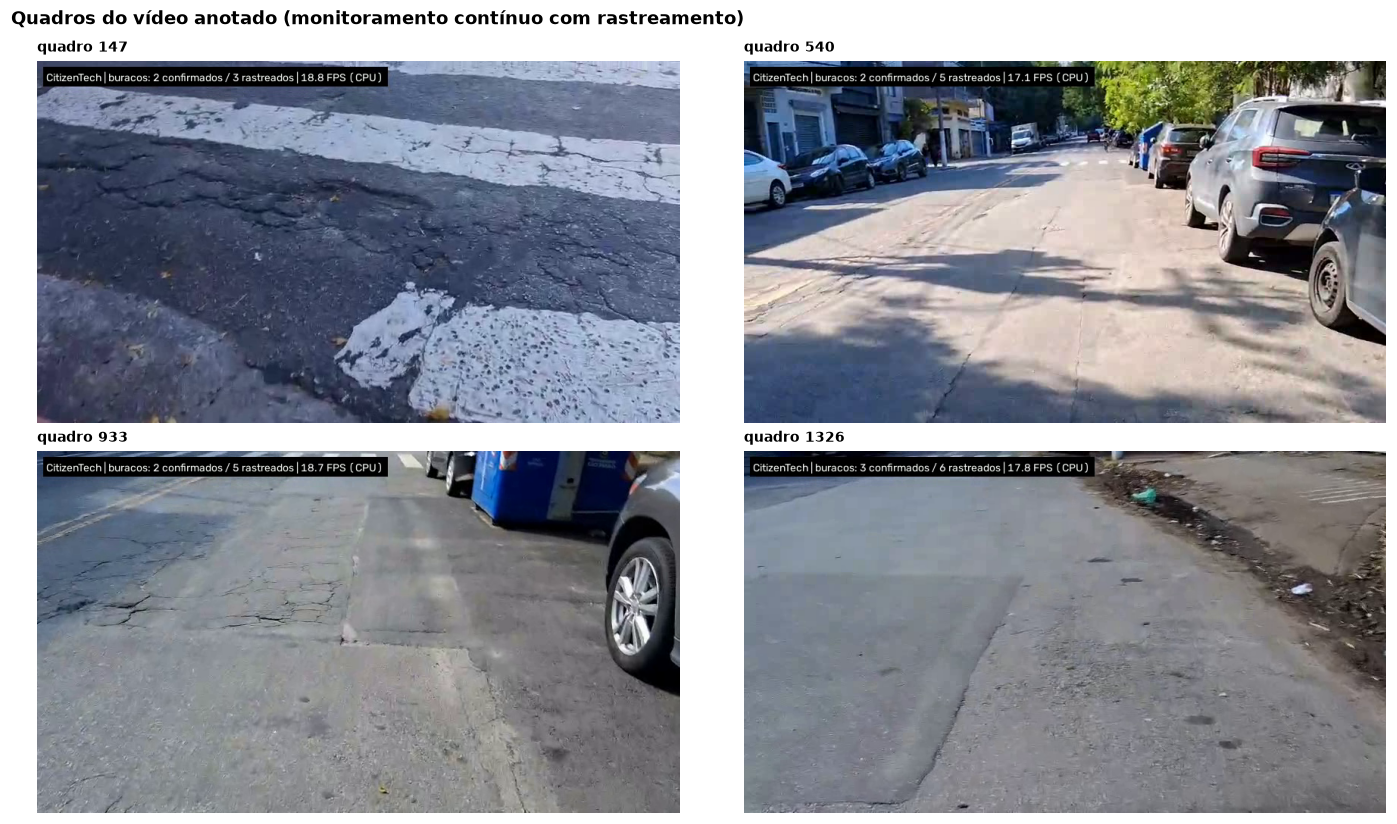

In [14]:
cap = cv2.VideoCapture(str(SAIDA)); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axs = plt.subplots(2, 2, figsize=(13, 7.6))
for ax, f in zip(axs.flat, np.linspace(total * 0.1, total * 0.9, 4).astype(int)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(f)); ok, fr = cap.read()
    if ok: ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
    ax.set_title(f"quadro {f}", fontsize=9, loc="left"); ax.axis("off")
cap.release()
plt.suptitle("Quadros do vídeo anotado (monitoramento contínuo com rastreamento)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig(EVID / "integracao_video.png", bbox_inches="tight"); plt.show()

### 5.2.1 Vídeo real da rua
Gravado caminhando, com sol forte e sombras. A via tem rachaduras e remendos, mas nenhum buraco fundo.

![Detecções no vídeo real](evidencias/video_real_deteccoes.jpg)

| Momento | Confiança | O que foi marcado |
|---|---|---|
| 4,2 s | 0,54 | meio-fio com folhas e sujeira |
| 7,8 s | 0,53 | faixa de pedestre desgastada sobre remendo |
| 20,6 s | 0,33 | sombra |
| 31 a 36 s | 0,29 a 0,43 | área de rachaduras e remendos |
| 41,8 s | 0,49 | sarjeta com sujeira |

As 3 detecções confirmadas são falsos positivos, causados principalmente pela mudança de domínio (ângulo, pavimento e iluminação diferentes do treino). Como a base de treino é toda em tons de cinza, testamos converter a entrada para cinza: o ganho no teste externo foi pequeno (mAP@0,5 de 0,368 para 0,384) e no vídeo os falsos positivos aumentaram, então a conversão foi descartada. O caminho é re-treinar com fotos coloridas da cidade, incluindo exemplos negativos.

### 5.2.2 Fotos reais
11 fotos de buracos tiradas pelo grupo com o celular (900×1600).

![Acertos nas fotos reais](evidencias/fotos_reais_acertos.jpg)
*Fotos 01, 03, 04, 09 e 10: buraco confirmado. Na 10, a tampa de bueiro também foi confirmada.*

![Erros nas fotos reais](evidencias/fotos_reais_erros.jpg)
*Fotos 02 e 05: só como incerto. Fotos 06, 07, 08 e 11: não detectado.*

| Resultado | Fotos | Total |
|---|---|---|
| Buraco confirmado (≥ 0,5) | 01, 03, 04, 09, 10 | 5 |
| Só como incerto (0,25 a 0,5) | 02, 05 | 2 |
| Não detectado | 06, 07, 08, 11 | 4 |
| Falso positivo confirmado | tampa de bueiro (10) | 1 |

O modelo acerta buracos com borda nítida ou água acumulada (confiança de 0,61 a 0,75) e erra buracos rasos, fotos muito próximas e tampas de bueiro. A taxa de 5 em 11 com limiar 0,5 é coerente com o recall do teste (0,49). Latência de 55 a 115 ms por foto. As imagens anotadas estão em `evidencias/fotos_reais/`.

### 5.3 Ranking de prioridade após a integração

,uid,nome,graves,leves,reportes,deteccoes_visao,conf_media_visao,umidade_media,pontuacao,nivel
0,SIM0002,"Av. Lins de Vasconcelos, 800-1200",2,1,1,0,NaN,62.5,9.0,alta
1,SIM0005,Via filmada pelo grupo (vídeo de 17/11/2026),0,0,0,3,0.55,NaN,6.0,media
2,SIM0004,"Av. Jabaquara, 500-900",0,0,0,2,0.64,NaN,4.0,media
3,SIM0003,"Rua Domingos de Morais, 2000-2400",0,2,0,0,NaN,92.0,2.4,baixa
4,SIM0001,"Rua Vergueiro, 1000-1400",0,0,0,0,NaN,58.0,0.0,sem_registro


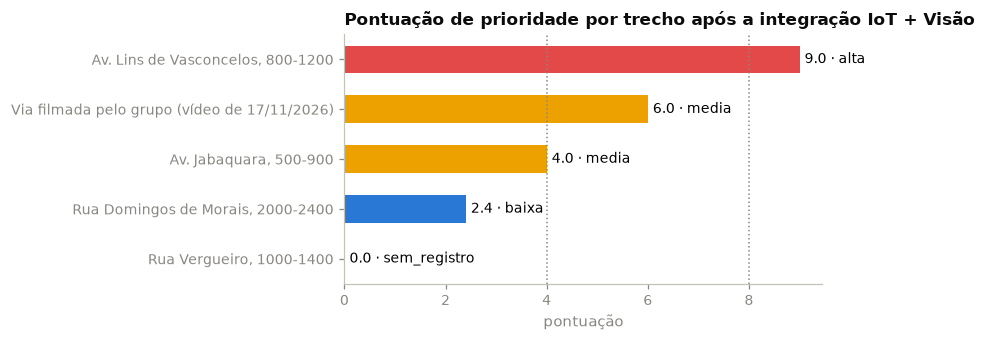

In [15]:
rank = pd.DataFrame(banco.prioridades(conn, apenas_com_registro=False))[["uid", "nome", "graves", "leves", "reportes", "deteccoes_visao", "conf_media_visao", "umidade_media", "pontuacao", "nivel"]]
display(rank)
fig, ax = plt.subplots(figsize=(8, 3.2))
cores = [PAL["vermelho"] if n == "alta" else PAL["amarelo"] if n == "media" else PAL["azul"] for n in rank["nivel"]]
ax.barh(rank["nome"][::-1], rank["pontuacao"][::-1], color=cores[::-1], height=0.55)
for y, (p, n) in enumerate(zip(rank["pontuacao"][::-1], rank["nivel"][::-1])): ax.text(p + 0.1, y, f"{p} · {n}", va="center", fontsize=9)
ax.axvline(4, color=PAL["cinza"], lw=1, ls=":"); ax.axvline(8, color=PAL["cinza"], lw=1, ls=":")
estilo(ax, "Pontuação de prioridade por trecho após a integração IoT + Visão", "pontuação"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(EVID / "ranking_apos_visao.png", bbox_inches="tight"); plt.show()

## 6. Conclusões

In [16]:
resultado = {
    "modelo": "YOLO11n (Ultralytics 8.4) ajustado a partir do COCO", "parametros_M": round(n_params / 1e6, 2), "gflops": round(gflops, 1),
    "epocas": int(len(res)), "melhor_epoca": int(melhor["epoch"]), "imgsz": 640, "dataset": tabela_dados.to_dict("records"),
    "teste": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in r_teste.items()},
    "teste_externo": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in r_ext.items()},
    "limiar": {"exibicao": CONF_EXIBICAO, "registro": CONF_REGISTRO, "melhor_f1": {"limiar": float(melhor_f1["limiar"]), "F1": round(float(melhor_f1["F1"]), 4)},
               "em_0_5": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in tot.items()}},
    "latencia": bench.round(2).to_dict("records"), "hardware": HARDWARE, "video": resumo_video,
}
(EVID / "metricas_visao.json").write_text(json.dumps(resultado, ensure_ascii=False, indent=1, default=str))
l640 = bench[bench["imgsz"] == 640].iloc[0]
display(Markdown(f'''
| Resultado | Valor |
|---|---|
| Teste (mesma base, 93 fotos) | precisão **{r_teste["precisão"]:.3f}** · recall **{r_teste["recall"]:.3f}** · mAP@0,5 **{r_teste["mAP@0,5"]:.3f}** · mAP@0,5:0,95 **{r_teste["mAP@0,5:0,95"]:.3f}** |
| Teste externo (outra base, 88 fotos) | precisão **{r_ext["precisão"]:.3f}** · recall **{r_ext["recall"]:.3f}** · mAP@0,5 **{r_ext["mAP@0,5"]:.3f}** · mAP@0,5:0,95 **{r_ext["mAP@0,5:0,95"]:.3f}** |
| Limiar de registro 0,5 (teste, IoU ≥ 0,5) | precisão {tot["precisão"]:.3f} · recall {tot["recall"]:.3f} · F1 {tot["F1"]:.3f} (melhor F1 {melhor_f1["F1"]:.3f} em {melhor_f1["limiar"]}) |
| Latência em CPU ({HARDWARE["cpu"]}) | **{l640["latencia_media_ms"]:.0f} ms/imagem a 640 px ({l640["fps"]:.1f} FPS)** · {bench[bench["imgsz"]==480].iloc[0]["latencia_media_ms"]:.0f} ms a 480 px · {bench[bench["imgsz"]==320].iloc[0]["latencia_media_ms"]:.0f} ms a 320 px |
| Vídeo | {resumo_video["quadros processados"]} quadros processados, {resumo_video["FPS de processamento"]} FPS, {resumo_video["buracos confirmados (≥0,5)"]} buracos únicos confirmados e gravados no banco |

Resumo salvo em `evidencias/metricas_visao.json`.
'''))


| Resultado | Valor |
|---|---|
| Teste (mesma base, 93 fotos) | precisão **0.755** · recall **0.626** · mAP@0,5 **0.703** · mAP@0,5:0,95 **0.421** |
| Teste externo (outra base, 88 fotos) | precisão **0.596** · recall **0.319** · mAP@0,5 **0.368** · mAP@0,5:0,95 **0.166** |
| Limiar de registro 0,5 (teste, IoU ≥ 0,5) | precisão 0.856 · recall 0.490 · F1 0.623 (melhor F1 0.712 em 0.25) |
| Latência em CPU (Intel(R) Core(TM) 7 240H) | **79 ms/imagem a 640 px (12.6 FPS)** · 49 ms a 480 px · 37 ms a 320 px |
| Vídeo | 737 quadros processados, 13.99 FPS, 3 buracos únicos confirmados e gravados no banco |

Resumo salvo em `evidencias/metricas_visao.json`.


**Resultados.** mAP@0,5 de 0,70 no teste (precisão 0,75, recall 0,63) e de 13 a 21 FPS a 640 px em CPU, conforme o modo de energia (bateria ou tomada). As detecções confirmadas vão para o banco e alteram o ranking usado pela zeladoria e pelo agente de GenAI; no vídeo, o rastreamento evita contar o mesmo buraco várias vezes.

**Limitações.** Base pequena e em tons de cinza; queda no teste externo (mAP@0,5 de 0,37) e falsos positivos no vídeo e nas fotos reais (tampas, sombras, remendos). O modelo não mede profundidade, que vem do sensor IoT e da vistoria. O rastreamento depende de câmera estável.

**Próximos passos.** Re-treinar com fotos locais e exemplos negativos, comparar com o YOLO11s, exportar para ONNX/OpenVINO e combinar a detecção com a profundidade medida pelo IoT.